# 06 — Validation: What Do Archetypes Add to the Five Positions?

**Project:** Positionless NBA Player Archetypes · **Season:** 2025-26 · **Population:** 379 players with ≥ 500 minutes

The previous notebooks built a data-driven description of playing style: three PCA axes, **3 families** and **8
archetypes** from k-means, and a list of statistical unicorns and border players. None of these steps ever looked at a
player's position. This final notebook brings the positions back and asks:

1. **Agreement.** How closely do the data-driven groups match the official positions? Are they a relabelling of
   positions, unrelated to them, or something in between?
2. **Added value.** For each style feature, how much of the variation between players does position explain, and how
   much do the archetypes explain? Where does the five-position system fall short?
3. **Predictability.** If a model only sees how a player plays, how well can it recover the listed position?
4. **Meaning.** What does each archetype look like in real units, and do archetypes describe *how* players play or *how
   well* they play?

| Section | Tool | Question it answers |
|---|---|---|
| §2 | **Adjusted Rand Index (ARI)** + permutation baseline | How similar are two partitions of the same players, compared with chance? |
| §3 | **Cross-tabulation read as a confusion matrix** (accuracy, precision, recall, F1) | If each archetype "predicts" its most common position, how often is it right? |
| §4 | **R² of a regression on group dummies** | What share of each style feature's variance does group membership explain? |
| §5 | **KNN and decision tree with stratified cross-validation** | How well can playing style predict position, compared with archetype and family? |
| §6 | **Silhouette** + PCA maps | Which labelling forms the most compact, separated groups in style space? |
| §7–8 | Group medians, boxplots, cross-tabulations | Archetype profiles and value; where unicorns and border players come from |

**Two versions of "position".** `pos` is the **listed** position (the roster label). `pos_played` is the position at
which the player logged the most minutes, estimated from play-by-play data. Using both prevents the conclusions from
depending on one imperfect label.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import (adjusted_rand_score, r2_score, accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, silhouette_score)
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 170)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style='whitegrid', context='notebook')

DATA = Path('../data') if Path('../data').exists() else Path('data')
POS_ORDER = ['PG', 'SG', 'SF', 'PF', 'C']
FAM_ORDER = ['On-Ball Creator', 'Off-Ball Perimeter', 'Big']
ORDER = ['Primary Creator', 'Shot-Making Guard', 'Secondary Scoring Wing', 'Spot-Up Floor Spacer',
         'Defensive Disruptor', 'Stretch Forward', 'Hub Big', 'Rim-Running Big']
FEAT = ['x3p_ar', 'corner3_rate', 'mid_share', 'rim_share', 'f_tr', 'usg_percent', 'ast_percent', 'tov_percent',
        'percent_assisted_x2p_fg', 'orb_percent', 'drb_percent', 'blk_percent', 'stl_percent']
SHOW = {'x3p_ar': '3PA rate', 'corner3_rate': 'corner-3 rate', 'mid_share': 'mid-range share',
        'rim_share': 'rim share', 'f_tr': 'FT rate', 'usg_percent': 'USG%', 'ast_percent': 'AST%',
        'tov_percent': 'TOV%', 'percent_assisted_x2p_fg': '% 2s assisted', 'orb_percent': 'ORB%',
        'drb_percent': 'DRB%', 'blk_percent': 'BLK%', 'stl_percent': 'STL%'}   # readable feature names
N_PERM = 1000            # label shuffles for the permutation baseline
SEED = 0                 # permutation baseline
CV_SEED = 42             # cross-validation folds and decision trees

---
## 1. Load and Align the Tables

**Goal.** Load the clustering results (families, archetypes, silhouette, PCA coordinates), the 13 style features in
two versions (power-transformed, as used for clustering; and raw, in real units), the anomaly classification, and the
full season table, which also contains efficiency and impact stats never used to build the archetypes (TS%, BPM,
WS/48, minutes).

**Why it matters.** Every comparison below pairs a label from one table with a value from another. A single
misaligned row would silently attach one player's archetype to another player's stats.

**What to look for.** All five tables have the same 379 players in the same order (checked with `assert`), and the
group sizes of each labelling.

In [2]:
arch = pd.read_csv(DATA / 'processed' / 'archetypes.csv')
power = pd.read_csv(DATA / 'processed' / 'features_power.csv')
raw = pd.read_csv(DATA / 'processed' / 'features_raw.csv')
anom = pd.read_csv(DATA / 'processed' / 'anomalies.csv')
full = pd.read_csv(DATA / 'processed' / 'nba_2025_26_mp500.csv')

for t in (power, raw, anom, full):
    assert (t['player_id'].values == arch['player_id'].values).all()
assert all(f in power.columns and f in raw.columns for f in FEAT)

X = power[FEAT].values                     # the clustering feature space
LABELS = {'listed position': arch['pos'], 'played position': arch['pos_played'],
          '3 families': arch['family'], '8 archetypes': arch['archetype']}
names = arch['player']
print('players:', len(arch), '| style features:', len(FEAT))
print('missing labels:', {k: int(v.isna().sum()) for k, v in LABELS.items()})
print()
for k, v in LABELS.items():
    print(f'{k:>16}:', ', '.join(f'{g} {n}' for g, n in v.value_counts().items()))

players: 379 | style features: 13
missing labels: {'listed position': 0, 'played position': 0, '3 families': 0, '8 archetypes': 0}

 listed position: SG 101, PF 74, C 68, PG 68, SF 68
 played position: SG 85, C 76, PF 75, SF 73, PG 70
      3 families: Off-Ball Perimeter 175, On-Ball Creator 132, Big 72
    8 archetypes: Primary Creator 61, Secondary Scoring Wing 57, Stretch Forward 56, Defensive Disruptor 50, Spot-Up Floor Spacer 48, Shot-Making Guard 45, Rim-Running Big 31, Hub Big 31


### Findings: Data
- The five tables are row-aligned on `player_id`, and no player is missing a listed position, a played position, a
  family or an archetype.
- Group sizes are reasonably balanced: positions have 68–101 players (SG is the largest), families 72–175, and
  archetypes 31–61. No grouping is dominated by a single giant group.

---
## 2. Agreement with Positions: Adjusted Rand Index

**Goal.** Measure how similar the data-driven groupings are to the positions with the **Adjusted Rand Index**. ARI
looks at every *pair* of players and asks whether the two partitions agree on putting them together or apart; it is
then adjusted so that **0 = agreement expected by chance** and **1 = identical partitions** (group names do not
matter, only who is grouped with whom).

**Why it matters.** If archetypes were just positions under new names, the whole pipeline would add nothing. If they
were unrelated to positions, they would probably be capturing noise rather than basketball roles. The interesting
answer is in between, and ARI places us on that scale.

**A reference point.** The two position labels themselves are compared too: listed vs. played position shows how much
two *versions of the same concept* agree.

**What to look for.** ARI of families and archetypes against both position labels, compared with the
position-vs.-position reference.

In [3]:
pairs = [('8 archetypes', 'listed position'), ('8 archetypes', 'played position'),
         ('3 families', 'listed position'), ('3 families', 'played position'),
         ('listed position', 'played position'), ('3 families', '8 archetypes')]
ari = pd.DataFrame([(a, b, adjusted_rand_score(LABELS[a], LABELS[b])) for a, b in pairs],
                   columns=['grouping', 'compared with', 'ARI'])
ari.round(3)

,grouping,compared with,ARI
0,8 archetypes,listed position,0.143
1,8 archetypes,played position,0.158
2,3 families,listed position,0.170
3,3 families,played position,0.177
4,listed position,played position,0.538
5,3 families,8 archetypes,0.264


**Goal.** Check that the ARI values are **meaningfully above chance** with a permutation baseline: shuffle the
archetype (or family) labels across players 1,000 times (fixed seed), keeping the group sizes fixed, and recompute
the ARI each time. The shuffles show the range of ARI values that pure chance produces for groups of these sizes.

**Why it matters.** A low ARI could mean "related but different" or "no relation at all". The permutation
distribution separates the two: if the observed ARI is far outside it, the relationship is real even though the
agreement is modest.

**What to look for.** Where the observed value sits relative to the null distribution, the largest ARI any shuffle
reached, and the permutation p-value = (number of shuffles with ARI ≥ observed + 1) / (1,000 + 1).

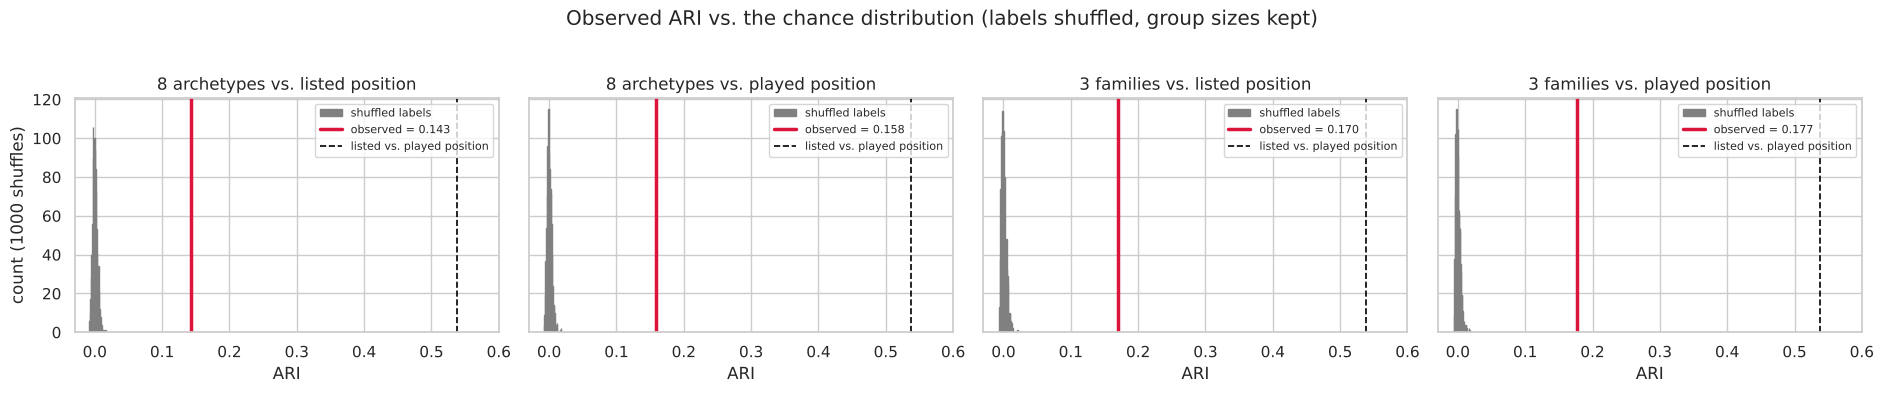

,grouping,compared with,observed ARI,null mean,null sd,null max,z vs. null,p (permutation)
0,8 archetypes,listed position,0.143,-0.0001,0.0035,0.0162,41.5,0.001
1,8 archetypes,played position,0.158,0.0000,0.0036,0.0181,43.9,0.001
2,3 families,listed position,0.170,0.0002,0.0038,0.0215,44.4,0.001
3,3 families,played position,0.177,0.0000,0.0034,0.0176,52.0,0.001


In [4]:
rng = np.random.default_rng(SEED)
perm_rows, null = [], {}
for a, b in pairs[:4]:
    x, y = LABELS[a].values, LABELS[b].values
    obs = adjusted_rand_score(x, y)
    null[(a, b)] = np.array([adjusted_rand_score(rng.permutation(x), y) for _ in range(N_PERM)])
    n = null[(a, b)]
    perm_rows.append({'grouping': a, 'compared with': b, 'observed ARI': obs, 'null mean': n.mean(),
                      'null sd': n.std(), 'null max': n.max(), 'z vs. null': (obs - n.mean()) / n.std(),
                      'p (permutation)': ((n >= obs).sum() + 1) / (N_PERM + 1)})
perm = pd.DataFrame(perm_rows)

fig, axes = plt.subplots(1, 4, figsize=(19, 3.8), sharey=True)
for ax, (a, b), r in zip(axes, pairs[:4], perm_rows):
    ax.hist(null[(a, b)], bins=30, color='grey', edgecolor='grey', label='shuffled labels')
    ax.axvline(r['observed ARI'], color='crimson', lw=2.5, label=f"observed = {r['observed ARI']:.3f}")
    ax.axvline(adjusted_rand_score(LABELS['listed position'], LABELS['played position']), color='black', ls='--',
               lw=1.2, label='listed vs. played position')
    ax.set(title=f'{a} vs. {b}', xlabel='ARI', xlim=(-0.03, 0.6))
    ax.legend(fontsize=8, loc='upper right')
axes[0].set_ylabel(f'count ({N_PERM} shuffles)')
plt.suptitle('Observed ARI vs. the chance distribution (labels shuffled, group sizes kept)', y=1.03)
plt.tight_layout(); plt.show()
perm.round({'observed ARI': 3, 'null mean': 4, 'null sd': 4, 'null max': 4, 'z vs. null': 1, 'p (permutation)': 4})

### Findings: Agreement with positions
- **Agreement is low but far above chance.** Archetypes vs. listed position give ARI = 0.14 and families vs. listed
  position 0.17; against the played position the values are slightly higher (0.16 and 0.18).
- **None of the 1,000 shuffles comes close.** Shuffled labels give ARI ≈ 0.000 ± 0.004, and the largest shuffled
  value is about 0.02. The observed values are 41–52 standard deviations above the null mean, and the permutation
  p-value is 0.001 in every case, the smallest value 1,000 shuffles can give.
- **For scale:** the two position labels agree with each other at ARI ≈ 0.54. Archetypes are much further from
  positions than one version of "position" is from another.
- ARI is also modest between the families and the archetypes (0.26), even though the archetypes nest roughly inside
  the families. ARI rewards partitions of the *same granularity*, so a 3-group and an 8-group labelling can never
  score highly against each other. ARI should therefore be read together with the cross-tabulations below.
- **Conclusion:** archetypes are **related to** positions (far from random) but are **not a relabelling** of them.

---
## 3. Cross-Tabulations Read as a Confusion Matrix

**Goal.** Cross-tabulate the 8 archetypes against the listed and the played position, as counts and as row
percentages (the share of each archetype coming from each position), and compute each archetype's **purity**: the
share of its players that come from its most common position.

**Why it matters.** ARI is a single number; the cross-tabulation shows the structure behind it. A concentrated row is
an archetype that corresponds to one position; a spread-out row is a role that several positions perform; a
spread-out column is a position that hides several different jobs.

**What to look for.** Rows dominated by one cell versus rows spread over three or four positions, and whether the
picture changes with the play-by-play position.

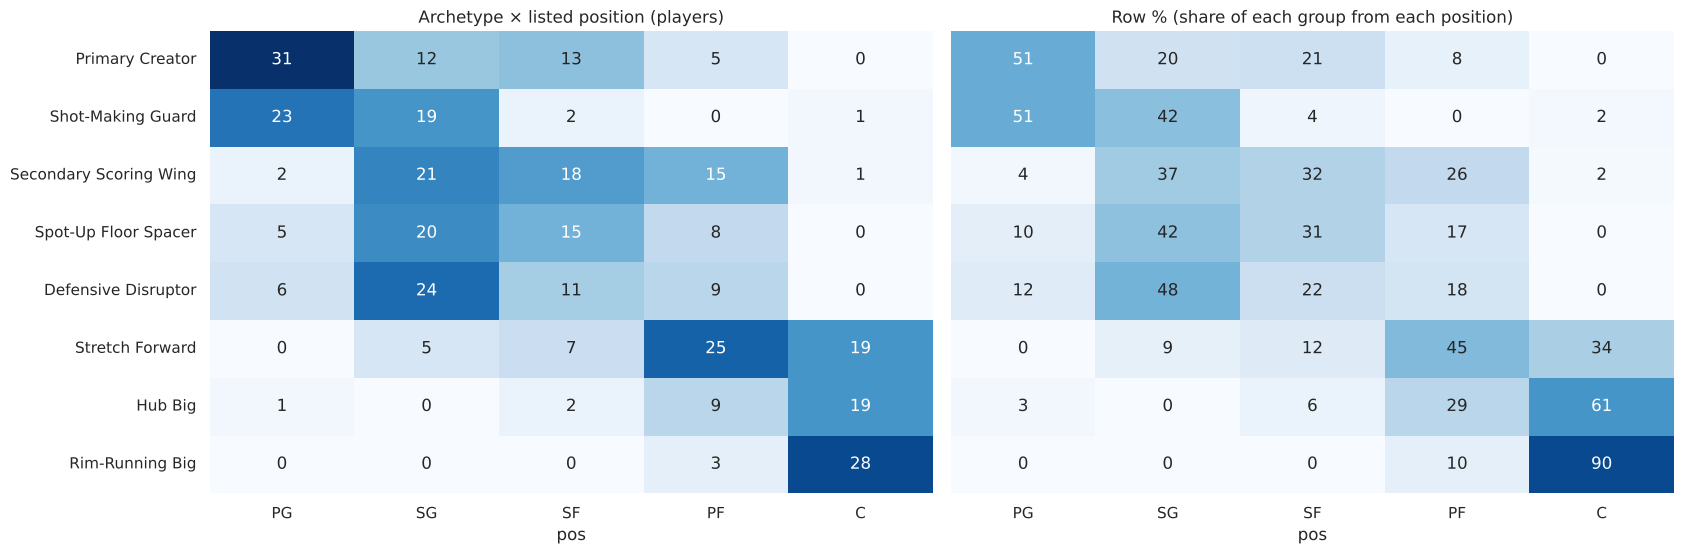

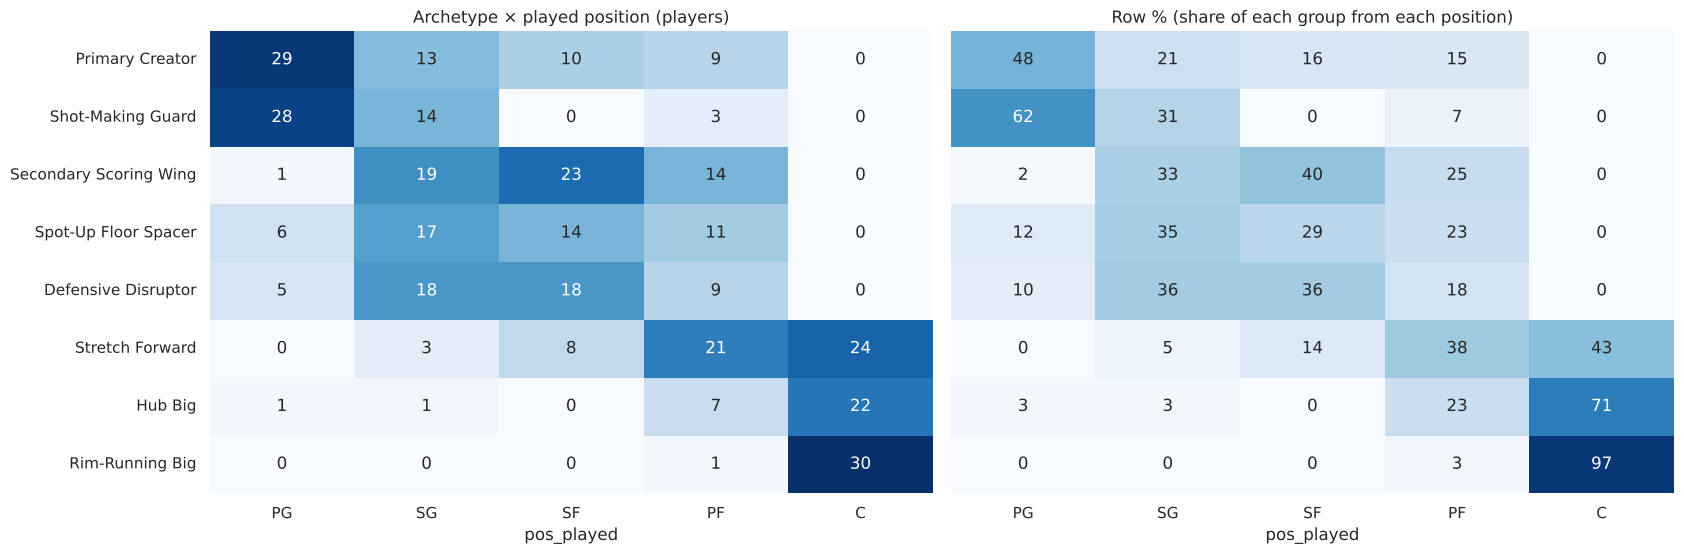

size-weighted mean purity (listed): 50%
size-weighted mean purity (played): 50%


,players,most common position,purity %,positions with ≥ 3 players,most common position (played),purity % (played)
archetype,,,,,,
Primary Creator,61,PG,51.0,4,PG,48.0
Shot-Making Guard,45,PG,51.0,2,PG,62.0
Secondary Scoring Wing,57,SG,37.0,3,SF,40.0
Spot-Up Floor Spacer,48,SG,42.0,4,SG,35.0
Defensive Disruptor,50,SG,48.0,4,SG,36.0
Stretch Forward,56,PF,45.0,4,C,43.0
Hub Big,31,C,61.0,2,C,71.0
Rim-Running Big,31,C,90.0,2,C,97.0


In [5]:
def heat_pair(table, title, cmap):
    pct = table.div(table.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(1, 2, figsize=(17, 0.55 * len(table) + 1.3))
    sns.heatmap(table, annot=True, fmt='d', cmap=cmap, cbar=False, ax=ax[0])
    ax[0].set(title=f'{title} (players)', ylabel='')
    sns.heatmap(pct, annot=True, fmt='.0f', cmap=cmap, cbar=False, vmin=0, vmax=100, ax=ax[1])
    ax[1].set(title='Row % (share of each group from each position)', ylabel='')
    ax[1].set_yticklabels([])
    plt.tight_layout(); plt.show()

ct = pd.crosstab(arch['archetype'], arch['pos']).loc[ORDER, POS_ORDER]
ct_played = pd.crosstab(arch['archetype'], arch['pos_played']).loc[ORDER, POS_ORDER]
heat_pair(ct, 'Archetype × listed position', 'Blues')
heat_pair(ct_played, 'Archetype × played position', 'Blues')

def purity(table):
    return pd.DataFrame({'players': table.sum(axis=1), 'most common position': table.idxmax(axis=1),
                         'purity %': (table.max(axis=1) / table.sum(axis=1) * 100).round(0),
                         'positions with ≥ 3 players': (table >= 3).sum(axis=1)})

pur = purity(ct).join(purity(ct_played)[['most common position', 'purity %']], rsuffix=' (played)')
for col, lab in [('purity %', 'listed'), ('purity % (played)', 'played')]:
    print(f'size-weighted mean purity ({lab}): {(pur[col] * pur["players"]).sum() / pur["players"].sum():.0f}%')
pur

**Goal.** Repeat the cross-tabulation at the coarser level: the **3 families** against the listed position.

**Why it matters.** Families are the statistically most robust level of the taxonomy. If even three broad families
cut across positions, the mismatch is not an artefact of choosing many archetypes.

**What to look for.** Whether each family maps onto a contiguous block of positions (guards → creators, bigs → Big) and
how many players fall outside that block.

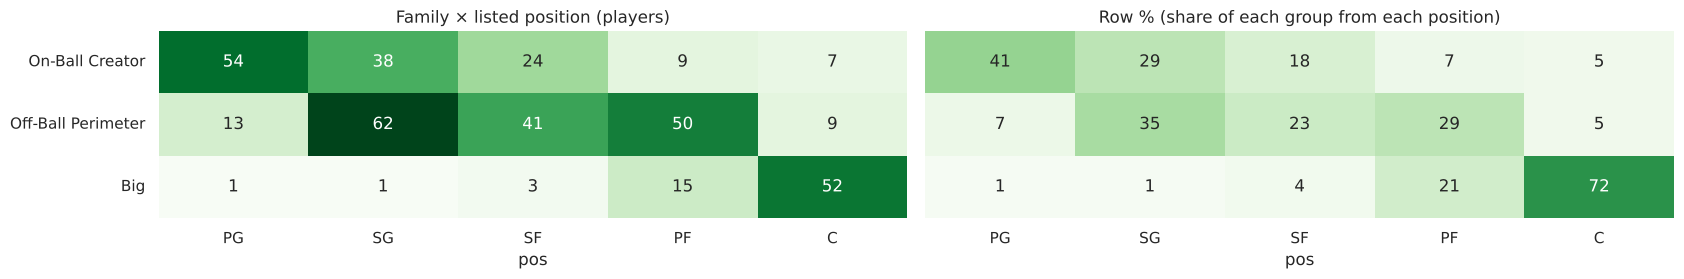

centres in the Big family: 52 of 68 (76%) | Big family listed C: 72%
share of each position in the On-Ball Creator family: {'PG': 0.79, 'SG': 0.38, 'SF': 0.35, 'PF': 0.12, 'C': 0.1}
share of each position in the Off-Ball Perimeter family: {'PG': 0.19, 'SG': 0.61, 'SF': 0.6, 'PF': 0.68, 'C': 0.13}


In [6]:
fam_ct = pd.crosstab(arch['family'], arch['pos']).loc[FAM_ORDER, POS_ORDER]
heat_pair(fam_ct, 'Family × listed position', 'Greens')
print(f"centres in the Big family: {fam_ct.loc['Big', 'C']} of {fam_ct['C'].sum()} "
      f"({fam_ct.loc['Big', 'C'] / fam_ct['C'].sum():.0%}) | Big family listed C: "
      f"{fam_ct.loc['Big', 'C'] / fam_ct.loc['Big'].sum():.0%}")
print('share of each position in the On-Ball Creator family:',
      (fam_ct.loc['On-Ball Creator'] / fam_ct.sum()).round(2).to_dict())
print('share of each position in the Off-Ball Perimeter family:',
      (fam_ct.loc['Off-Ball Perimeter'] / fam_ct.sum()).round(2).to_dict())

**Goal.** Read the archetype × position table as a **confusion matrix**. Treat each archetype as a "prediction" of
position: map every archetype to its most common listed position (the **majority mapping**), predict that position
for all of its players, and score the predictions with **accuracy**, and **precision, recall and F1 per position**.

- **Precision** for a position: of the players the archetypes "call" PG, the share who really are listed PG.
- **Recall**: of the players listed PG, the share the archetypes call PG.
- **F1**: the harmonic mean of the two; **macro F1** averages it over the five positions with equal weight.

**Why it matters.** This turns the cross-tabulation into the standard language of classification. But the
interpretation is different from a normal classifier: the archetypes were never trained to predict positions. A low
score does **not** mean the clustering failed; it means that **positions hide several roles**, and that one role is
shared by several positions, so the archetype system is not a relabelling of positions.

**What to look for.** Which positions are recovered well (high recall and precision) and whether any position is
never predicted at all because no archetype is mostly made of it.

majority mapping: {'Primary Creator': 'PG', 'Shot-Making Guard': 'PG', 'Secondary Scoring Wing': 'SG', 'Spot-Up Floor Spacer': 'SG', 'Defensive Disruptor': 'SG', 'Stretch Forward': 'PF', 'Hub Big': 'C', 'Rim-Running Big': 'C'}
accuracy 0.504 | macro F1 0.447

              precision    recall  f1-score   support

          PG       0.51      0.79      0.62        68
          SG       0.42      0.64      0.51       101
          SF       0.00      0.00      0.00        68
          PF       0.45      0.34      0.38        74
           C       0.76      0.69      0.72        68

    accuracy                           0.50       379
   macro avg       0.43      0.49      0.45       379
weighted avg       0.43      0.50      0.45       379

played position (own majority mapping): accuracy 0.504 | macro F1 0.434


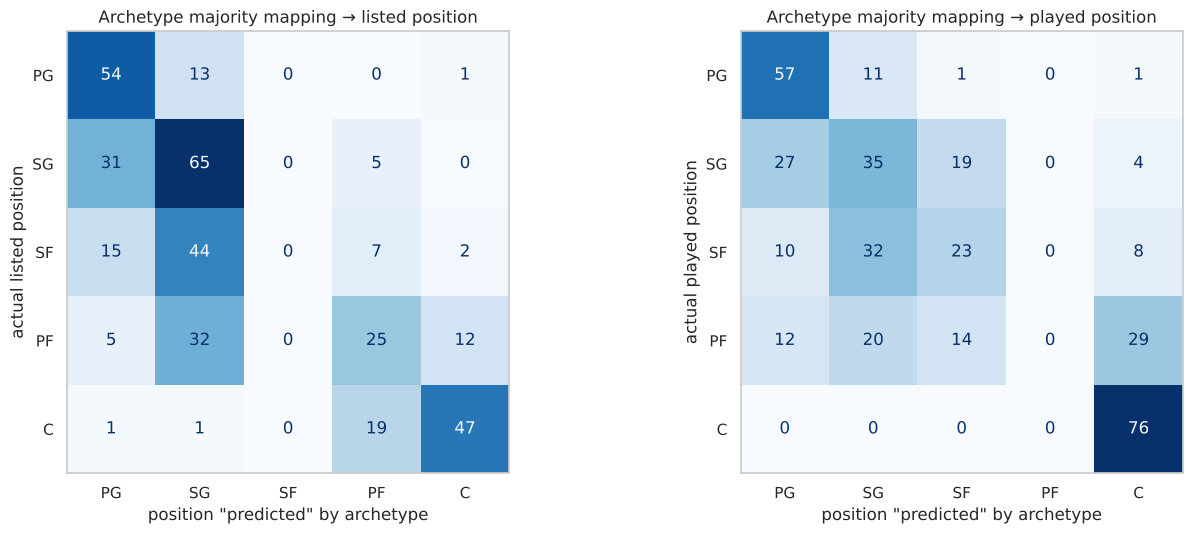

In [7]:
mapping = ct.idxmax(axis=1)
pred = arch['archetype'].map(mapping)
print('majority mapping:', mapping.to_dict())
acc_cm = accuracy_score(arch['pos'], pred)
f1_cm = f1_score(arch['pos'], pred, average='macro', zero_division=0)
print(f'accuracy {acc_cm:.3f} | macro F1 {f1_cm:.3f}')
print()
print(classification_report(arch['pos'], pred, labels=POS_ORDER, zero_division=0, digits=2))

map_played = ct_played.idxmax(axis=1)
pred_played = arch['archetype'].map(map_played)
acc_cm_played = accuracy_score(arch['pos_played'], pred_played)
f1_cm_played = f1_score(arch['pos_played'], pred_played, average='macro', zero_division=0)
print(f'played position (own majority mapping): accuracy {acc_cm_played:.3f} | macro F1 {f1_cm_played:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, y, p, t in [(ax[0], arch['pos'], pred, 'listed position'), (ax[1], arch['pos_played'], pred_played, 'played position')]:
    ConfusionMatrixDisplay.from_predictions(y, p, labels=POS_ORDER, cmap='Blues', colorbar=False, ax=a)
    a.set(title=f'Archetype majority mapping → {t}', xlabel='position "predicted" by archetype',
          ylabel=f'actual {t}')
    a.grid(False)
plt.tight_layout(); plt.show()

### Findings: Cross-tabulations and confusion matrix
- **Only one archetype is essentially a position.** Rim-Running Big is 90% listed centres (28 of 31). Every other
  archetype has a purity of about 60% or less, and **Secondary Scoring Wing is the least pure (37%)**, drawing at
  least 15 players each from SF, SG and PF. Weighted by size, the average archetype is only half made of its most
  common position (50%, for both listed and played position).
- **Most archetypes span three or four positions.** Primary Creator, Spot-Up Floor Spacer, Defensive Disruptor and
  Stretch Forward each take at least three players from four different positions.
- **Centres split three ways** (Rim-Running Big, Hub Big, Stretch Forward with 28, 19 and 19 listed centres), and
  **Primary Creator is not a point-guard archetype**: 31 of its 61 players are listed PG, the other 30 SG, SF or PF.
- **Using the played position changes little.** Shot-Making Guards look more like point guards (purity 51% → 62%)
  and the most common position of Stretch Forwards becomes C instead of PF.
- **Families cut across positions too.** Big is 72% listed centres and holds 76% of all centres. On-Ball Creator holds
  79% of point guards but draws from all five positions, and Off-Ball Perimeter holds the majority of SG, SF and PF
  players.
- **As a confusion matrix:** the majority mapping (Primary Creator and Shot-Making Guard → PG; Secondary Scoring Wing,
  Spot-Up Floor Spacer and Defensive Disruptor → SG; Stretch Forward → PF; Hub Big and Rim-Running Big → C) is right
  for **50% of players** (accuracy 0.50, macro F1 0.45). Against the played position the accuracy is also 0.50
  (macro F1 0.43).
  - **C is recovered best** (precision 0.76, recall 0.69), then PG (recall 0.79, precision 0.51).
  - **SF is never predicted** (recall 0): no archetype is mostly listed small forwards, so the listed SF is not a role
    in the data; small forwards are spread over the wing and creator archetypes.
  - With the **played** position the mapping changes at the forward spots: Secondary Scoring Wing becomes the SF
    archetype, Stretch Forward becomes a C archetype, and now **PF is never predicted**. Every centre by minutes is
    recovered (76 of 76), but the forward positions are where positions and roles disagree most, whichever position
    label is used.
- **Reading:** the low score does not mean the clustering failed. It means positions and archetypes cut the league
  differently: one position hides several roles, and one role is shared by several positions.

---
## 4. What Do Archetypes Explain That Positions Don't? (R² on Group Dummies)

**Goal.** For each of the 13 style features (in real units), fit a **linear regression on one-hot dummies** of a
grouping (`pd.get_dummies(..., drop_first=True)` with an intercept) and record its **R²**. This is done for the
listed position (5 groups), the 8 archetypes and the 3 families.

**How to read R² here.** With only dummies as inputs, the regression's prediction for every player is simply their
group's mean. R² is therefore the **share of the feature's variance explained by group membership**: 0 means the
groups have identical means, 1 means every player equals their group mean. Dropping one dummy avoids perfect
collinearity with the intercept; it does not change the predictions or R².

**Why it matters.** This is the key quantitative comparison of the project. ARI tells us that archetypes differ from
positions; R² tells us **which aspects of style** each system captures, feature by feature.

**What to look for.** Features where position does well (expected: size-related features such as rebounding, rim
share and blocks) and features where it does poorly (expected: on-ball creation such as usage). Do the archetypes do
better everywhere, or are there features where position wins?

In [8]:
def group_r2(y, groups):
    y = pd.Series(np.asarray(y, dtype=float))
    g = pd.Series(np.asarray(groups))
    ok = y.notna() & g.notna()
    D = pd.get_dummies(g[ok], drop_first=True).astype(float)
    model = LinearRegression().fit(D, y[ok])            # intercept + (groups − 1) dummies
    return r2_score(y[ok], model.predict(D))

R2_LABELS = {k: LABELS[k] for k in ['listed position', '8 archetypes', '3 families']}
r2 = pd.DataFrame({k: [group_r2(raw[f], lab) for f in FEAT] for k, lab in R2_LABELS.items()}, index=FEAT)
r2['archetypes − position'] = r2['8 archetypes'] - r2['listed position']
mean_r2 = r2[list(R2_LABELS)].mean().rename('mean R² over 13 features').to_frame()
display(mean_r2.round(3))
r2.sort_values('listed position', ascending=False).rename(index=SHOW).round(3)

,mean R² over 13 features
listed position,0.274
8 archetypes,0.543
3 families,0.391


,listed position,8 archetypes,3 families,archetypes − position
ORB%,0.546,0.704,0.607,0.159
DRB%,0.533,0.506,0.339,-0.027
BLK%,0.464,0.503,0.401,0.040
AST%,0.356,0.588,0.474,0.232
% 2s assisted,0.354,0.651,0.512,0.297
rim share,0.335,0.705,0.522,0.370
3PA rate,0.267,0.720,0.541,0.453
corner-3 rate,0.218,0.644,0.563,0.426
FT rate,0.152,0.439,0.263,0.286
TOV%,0.113,0.246,0.099,0.133


**Goal.** Visualise the comparison: one group of bars per feature, sorted by how well the listed position explains it.

**What to look for.** The gap between the grey bars (position) and the coloured bars (families, archetypes), and
whether it is largest for the creation and defence features.

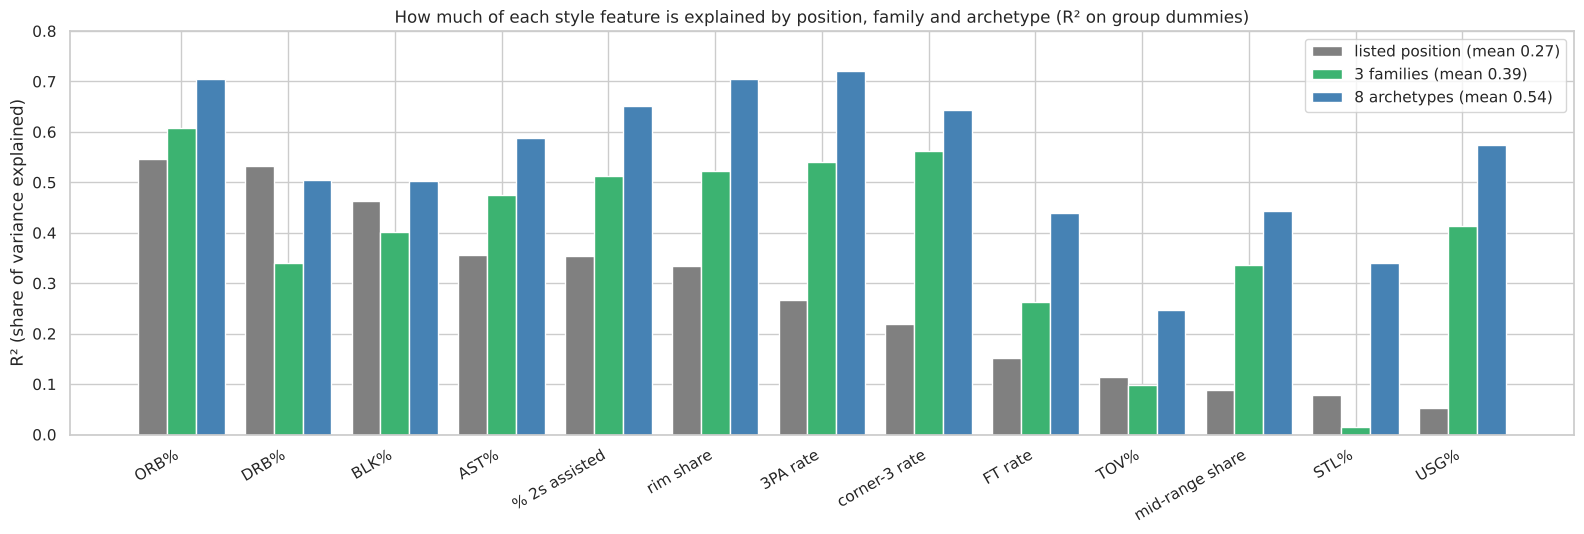

In [9]:
order = r2.sort_values('listed position', ascending=False).index
cols = {'listed position': 'grey', '3 families': 'mediumseagreen', '8 archetypes': 'steelblue'}
w = 0.27
xs = np.arange(len(order))
fig, ax = plt.subplots(figsize=(16, 5.5))
for j, (k, c) in enumerate(cols.items()):
    ax.bar(xs + (j - 1) * w, r2.loc[order, k], width=w, color=c, label=f'{k} (mean {r2[k].mean():.2f})')
ax.set_xticks(xs); ax.set_xticklabels([SHOW[f] for f in order], rotation=30, ha='right')
ax.set(ylabel='R² (share of variance explained)', ylim=(0, 0.8),
       title='How much of each style feature is explained by position, family and archetype (R² on group dummies)')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

**Goal.** A fairness check. The archetypes were **built from these same 13 features**, so they are bound to explain
them well. A fairer test uses **held-out descriptors of style that were never used for clustering**: average shot
distance, dunk share, total rebound rate, points per 100 possessions, share of made threes assisted, fouls per 100,
and the share of shots from 3–10 feet.

**What to look for.** Whether archetypes still beat positions on features they were not built from.

In [10]:
HELD_OUT = {'avg_dist_fga': 'average shot distance', 'percent_dunks_of_fga': 'dunks share of FGA',
            'trb_percent': 'total rebound %', 'pts_per_100_poss': 'points per 100 poss.',
            'percent_assisted_x3p_fg': '% of made 3s assisted', 'pf_per_100_poss': 'fouls per 100 poss.',
            'percent_fga_from_x3_10_range': 'share of FGA from 3–10 ft'}
held = pd.DataFrame({k: [group_r2(full[c], lab) for c in HELD_OUT] for k, lab in R2_LABELS.items()},
                    index=HELD_OUT.values())
held['archetypes − position'] = held['8 archetypes'] - held['listed position']
print('missing values skipped (players without a made 3):',
      {v: int(full[c].isna().sum()) for c, v in HELD_OUT.items() if full[c].isna().any()})
print('mean R² on held-out features:', held[list(R2_LABELS)].mean().round(3).to_dict())
held.round(3)

missing values skipped (players without a made 3): {'% of made 3s assisted': 16}
mean R² on held-out features: {'listed position': 0.281, '8 archetypes': 0.532, '3 families': 0.401}


,listed position,8 archetypes,3 families,archetypes − position
average shot distance,0.332,0.731,0.550,0.399
dunks share of FGA,0.360,0.661,0.496,0.302
total rebound %,0.641,0.664,0.524,0.023
points per 100 poss.,0.021,0.450,0.288,0.429
% of made 3s assisted,0.326,0.582,0.498,0.256
fouls per 100 poss.,0.149,0.234,0.176,0.085
share of FGA from 3–10 ft,0.137,0.402,0.278,0.265


### Findings: Variance explained
- **Archetypes explain about twice as much style variance as positions.** Averaged over the 13 features, R² is
  **0.27 for the listed position**, 0.39 for the 3 families and **0.54 for the 8 archetypes**.
- **Even 3 families beat 5 positions** (0.39 vs. 0.27), so the gain is not just a matter of having more groups.
- **Where position works:** the size features. Offensive and defensive rebounding (R² ≈ 0.55 and 0.53) and block rate
  (0.46) are the features position explains best.
- **Where position fails:** usage (R² ≈ 0.05), steal rate (0.08), mid-range share (0.09), turnover rate (0.11) and
  free-throw rate (0.15). Knowing a player's position says almost nothing about how much of the offense runs through
  them; archetypes explain usage more than ten times better (0.57).
- **Position wins on one feature.** Defensive rebounding is explained slightly *better* by position (0.53) than by
  archetypes (0.51), and block rate is close (0.46 vs. 0.50). Height, which positions encode, drives these stats
  directly, while the archetypes split bigs by offensive role rather than by size.
- **The gain holds on held-out style descriptors** never used in clustering (mean R² 0.28 for position vs. 0.53 for
  archetypes): e.g. points per 100 possessions, R² ≈ 0.02 vs. 0.45. Total rebound rate is again the exception,
  explained about equally well by both (0.64 vs. 0.66).
- **Conclusion:** the five positions describe **size** well and **creation and disruption** poorly, the same split
  PCA found (position tracks PC1 but hardly PC2–PC3).

---
## 5. Supervised Check: Can Playing Style Predict Position?

**Goal.** Use the 13 power-transformed style features as inputs and train two classifiers to predict three targets:
(a) **listed position**, (b) **archetype** (8 classes) and (c) **family** (3 classes). The models are a
**k-nearest-neighbours classifier** (K swept from 1 to 30) and a **decision tree** (`max_depth` swept from 1 to 15).
Every setting is evaluated with **5-fold stratified cross-validation** (shuffled, `random_state=42`), so each player is
predicted by a model that never saw them, and every fold keeps the class proportions. A **majority-class baseline**
(always predict the most common class) shows what "no information" scores.

**Why it matters.** This asks the validation question from the other direction: if a scout knew only *how* a player
plays (shot diet, creation, rebounding, defensive events), how reliably could they name the position on the roster?

**An important caveat.** The archetypes and families were **built from these same 13 features** by k-means, so they
are, by construction, regions of this feature space. Predicting them well is expected and partly circular: their
scores act as a **ceiling** for how predictable a style-based label can be. The meaningful result is how well the
**listed position** can be predicted, compared with that ceiling and with the baseline.

**What to look for.** The cross-validated accuracy and macro F1 at the best K / depth for each target, relative to its
baseline, and the shape of the curves (KNN: very small K overfits; trees: deep trees overfit).

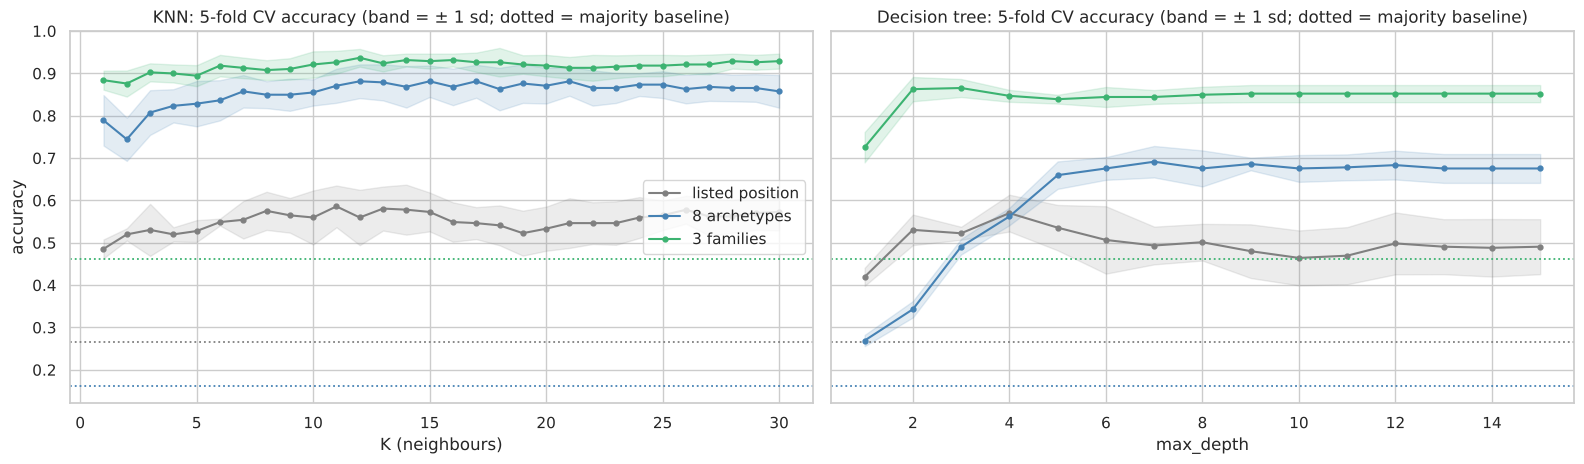

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=CV_SEED)
TARGETS = {'listed position': arch['pos'], '8 archetypes': arch['archetype'], '3 families': arch['family']}
K_GRID, DEPTH_GRID = range(1, 31), range(1, 16)

def cv_scores(model, y):
    s = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'f1_macro'])
    return s['test_accuracy'], s['test_f1_macro']

sweep = []
for t, y in TARGETS.items():
    for k in K_GRID:
        acc, f1 = cv_scores(KNeighborsClassifier(n_neighbors=k), y)
        sweep.append((t, 'KNN', k, acc.mean(), acc.std(), f1.mean(), f1.std()))
    for d in DEPTH_GRID:
        acc, f1 = cv_scores(DecisionTreeClassifier(max_depth=d, random_state=CV_SEED), y)
        sweep.append((t, 'Decision tree', d, acc.mean(), acc.std(), f1.mean(), f1.std()))
sweep = pd.DataFrame(sweep, columns=['target', 'model', 'setting', 'acc', 'acc_sd', 'f1', 'f1_sd'])

base = {}
for t, y in TARGETS.items():
    majority = y.value_counts().idxmax()
    accs, f1s = [], []
    for _, te in cv.split(X, y):
        p = np.full(len(te), majority, dtype=object)
        accs.append(accuracy_score(y.iloc[te], p)); f1s.append(f1_score(y.iloc[te], p, average='macro'))
    base[t] = (majority, np.mean(accs), np.std(accs), np.mean(f1s))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
pal = {'listed position': 'grey', '8 archetypes': 'steelblue', '3 families': 'mediumseagreen'}
for a, m, xl in [(ax[0], 'KNN', 'K (neighbours)'), (ax[1], 'Decision tree', 'max_depth')]:
    for t in TARGETS:
        s = sweep[(sweep['target'] == t) & (sweep['model'] == m)]
        a.plot(s['setting'], s['acc'], marker='o', ms=3.5, color=pal[t], label=t)
        a.fill_between(s['setting'], s['acc'] - s['acc_sd'], s['acc'] + s['acc_sd'], color=pal[t], alpha=0.15)
        a.axhline(base[t][1], color=pal[t], ls=':', lw=1.3)
    a.set(title=f'{m}: 5-fold CV accuracy (band = ± 1 sd; dotted = majority baseline)', xlabel=xl)
ax[0].set_ylabel('accuracy'); ax[0].legend(loc='center right')
plt.tight_layout(); plt.show()

**Goal.** Summarise the sweep: for each target and model, the setting with the highest mean cross-validated accuracy,
with mean ± standard deviation over the five folds for accuracy and macro F1, next to the majority baseline.

**What to look for.** How far each target rises above its baseline, and how far the listed position stays below the
archetype and family ceilings.

In [12]:
best = (sweep.loc[sweep.groupby(['target', 'model'])['acc'].idxmax()]
        .set_index(['target', 'model']).loc[list(TARGETS)])
best['accuracy'] = best.apply(lambda r: f"{r['acc']:.3f} ± {r['acc_sd']:.3f}", axis=1)
best['macro F1'] = best.apply(lambda r: f"{r['f1']:.3f} ± {r['f1_sd']:.3f}", axis=1)
best['best setting'] = [f"K = {s}" if m == 'KNN' else f"depth = {s}" for (_, m), s in zip(best.index, best['setting'])]
base_tab = pd.DataFrame({t: {'majority class': b[0], 'baseline accuracy': f'{b[1]:.3f} ± {b[2]:.3f}',
                             'baseline macro F1': f'{b[3]:.3f}'} for t, b in base.items()}).T
display(base_tab)
best[['best setting', 'accuracy', 'macro F1']]

,majority class,baseline accuracy,baseline macro F1
listed position,SG,0.266 ± 0.005,0.084
8 archetypes,Primary Creator,0.161 ± 0.005,0.035
3 families,Off-Ball Perimeter,0.462 ± 0.002,0.211


best setting       accuracy       macro F1
target          model                                                   
listed position Decision tree    depth = 4  0.570 ± 0.043  0.562 ± 0.043
                KNN                 K = 11  0.586 ± 0.049  0.584 ± 0.047
8 archetypes    Decision tree    depth = 7  0.691 ± 0.037  0.692 ± 0.036
                KNN                 K = 17  0.881 ± 0.039  0.869 ± 0.036
3 families      Decision tree    depth = 3  0.865 ± 0.021  0.854 ± 0.019
                KNN                 K = 12  0.937 ± 0.021  0.921 ± 0.033

### Findings: Supervised check
- **Listed position is only moderately predictable from style.** The best KNN (K = 11) reaches **0.59 ± 0.05
  accuracy** (macro F1 0.58) and the best tree (depth 4) 0.57 ± 0.04. That is well above the majority baseline of
  0.27 (always "SG", macro F1 0.08), so style does carry information about position, but **about four players in ten
  are assigned the wrong position** by a model that knows exactly how they play.
- **Archetypes and families are far more predictable**: KNN reaches **0.88 ± 0.04** for the 8 archetypes (baseline
  0.16) and **0.94 ± 0.02** for the 3 families (baseline 0.46). As stated above, this is expected and partly circular,
  because they were defined from these features; these numbers mark the ceiling for a label that really is a region of
  style space.
- **The gap is the finding.** Even with eight classes against five, an archetype is much easier to infer from playing
  style than a position is. The position label carries information that is not about style (height, roster
  conventions, the coach's lineup choices), and misses style information that the archetypes capture.
- KNN beats the decision tree for every target, and by most for the archetypes (0.88 vs. 0.69). k-means groups
  are defined by distances in this space, which suits a distance-based classifier, while a tree has to approximate
  them with axis-parallel splits.
- The curves behave as expected. For KNN, very small K (1–2) scores lowest for every target and accuracy is fairly
  flat beyond K ≈ 10. For the trees, position accuracy peaks at depth 4 and falls back to about 0.47–0.50 at larger
  depths as the trees overfit, while archetype and family accuracy plateau.

---
## 6. Silhouette by Labelling, and the Two Maps Side by Side

**Goal.** Compute the average **silhouette** of the players in the 13-feature power-transformed space using four
different labellings: listed position, played position, archetypes and families. For each player,
s = (b − a) / max(a, b), where *a* is the mean distance to their own group and *b* the mean distance to the nearest
other group; the average ranges from −1 to 1.

**Why it matters.** The silhouette measures whether a labelling forms **compact, separated groups in style space**.
k-means labels are optimised for this space, so they should score higher; the question is how close the positions
come, and whether they are better than an arbitrary split at all (silhouette near 0).

**What to look for.** The size of the gap between positions and the data-driven groups. Then, on the PCA map, how
much the position groups overlap compared with the archetypes.

In [13]:
sil = pd.Series({k: silhouette_score(X, lab) for k, lab in LABELS.items()}, name='average silhouette')
sil.round(3).to_frame()

,average silhouette
listed position,0.023
played position,0.025
3 families,0.205
8 archetypes,0.134


**Goal.** Plot the players on the first two PCA axes (PC1: perimeter ↔ interior; PC2: off-ball ↔ on-ball creator)
twice, coloured by listed position and by archetype, with each group's **median** marked by an X.

**What to look for.** Position medians lined up along PC1 only (a size scale), versus archetype medians spread over
both axes.

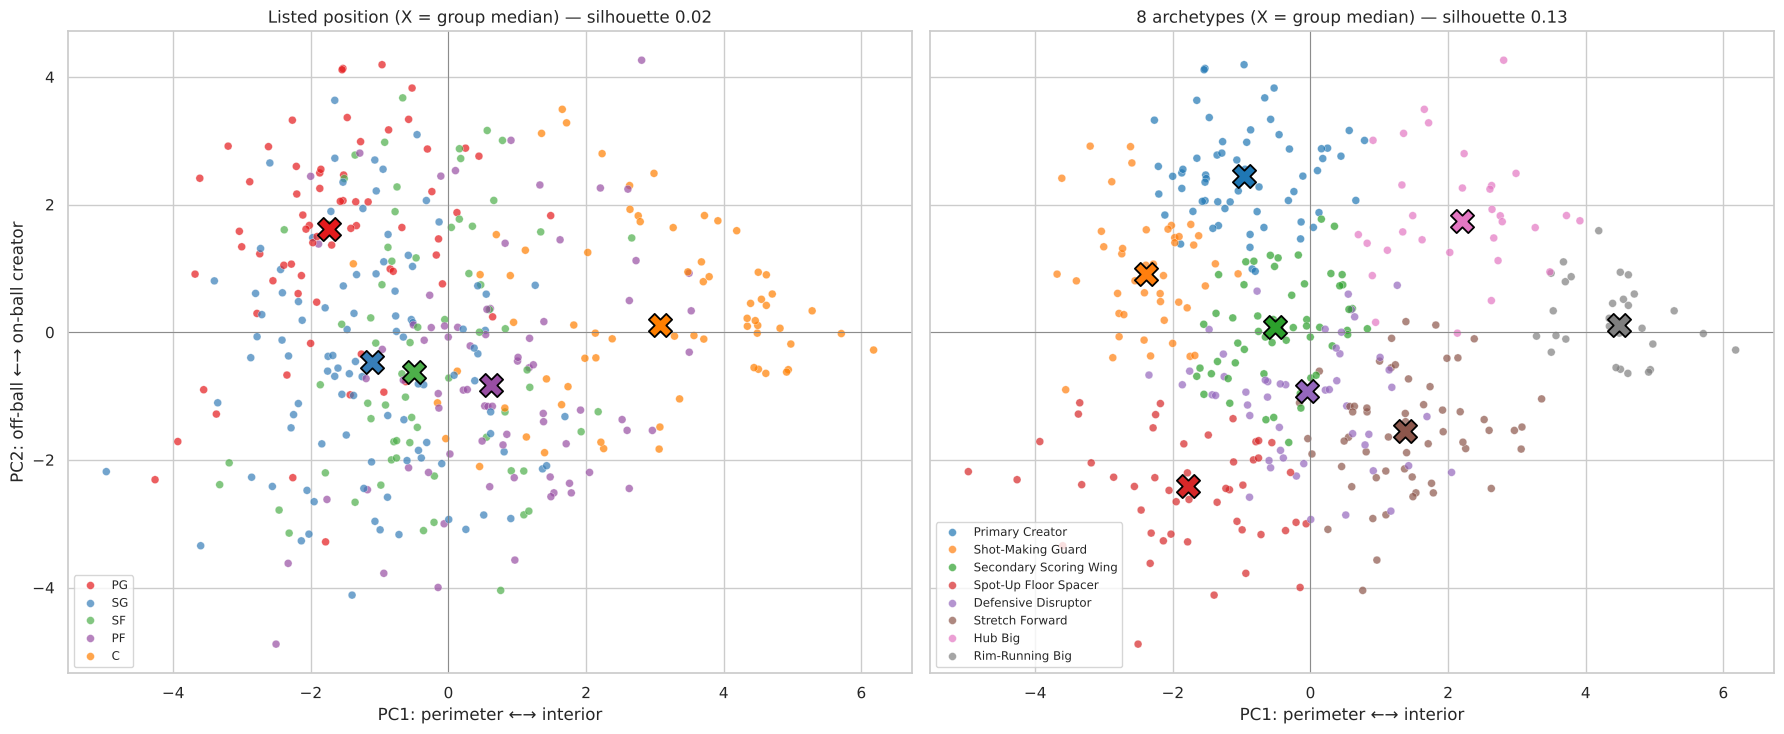

position medians on the map:
pos    PG    SG    SF    PF     C
PC1 -1.74 -1.12 -0.50  0.62  3.07
PC2  1.62 -0.46 -0.62 -0.82  0.11
PC1 / PC2 range of the group medians:
        pos: PC1 -1.74 … +3.07 | PC2 -0.82 … +1.62
  archetype: PC1 -2.39 … +4.49 | PC2 -2.41 … +2.45


In [14]:
POS_PAL = dict(zip(POS_ORDER, sns.color_palette('Set1', 5)))
ARCH_PAL = dict(zip(ORDER, sns.color_palette('tab10', 8)))
fig, ax = plt.subplots(1, 2, figsize=(18, 7.5), sharex=True, sharey=True)
for a, col, order_, pal, title in [(ax[0], 'pos', POS_ORDER, POS_PAL, 'Listed position'),
                                   (ax[1], 'archetype', ORDER, ARCH_PAL, '8 archetypes')]:
    sns.scatterplot(data=arch, x='PC1', y='PC2', hue=col, hue_order=order_, palette=pal, s=32, alpha=0.7,
                    edgecolor='white', linewidth=0.3, ax=a)
    med = arch.groupby(col)[['PC1', 'PC2']].median()
    for g, (px, py) in med.iterrows():
        a.scatter(px, py, s=280, marker='X', color=pal[g], edgecolor='black', linewidth=1.3, zorder=5)
    a.axhline(0, color='grey', lw=0.6); a.axvline(0, color='grey', lw=0.6)
    a.set(title=f'{title} (X = group median) — silhouette {sil["listed position" if col == "pos" else "8 archetypes"]:.2f}',
          xlabel='PC1: perimeter ←→ interior', ylabel='PC2: off-ball ←→ on-ball creator')
    a.legend(title=None, loc='lower left', fontsize=8.5)
plt.tight_layout(); plt.show()

print('position medians on the map:')
print(arch.groupby('pos')[['PC1', 'PC2']].median().loc[POS_ORDER].round(2).T.to_string())
print('PC1 / PC2 range of the group medians:')
for col in ['pos', 'archetype']:
    med = arch.groupby(col)[['PC1', 'PC2']].median()
    print(f'  {col:>9}: PC1 {med["PC1"].min():+.2f} … {med["PC1"].max():+.2f} | PC2 {med["PC2"].min():+.2f} … {med["PC2"].max():+.2f}')

### Findings: Silhouette and maps
- **Positions barely form groups in style space.** The average silhouette is **0.023** for the listed position and
  0.025 for the played position: hardly better than an arbitrary split. The archetypes reach **0.13** and the families
  **0.21**.
- Even the data-driven labels have low silhouettes, the continuum seen in the clustering notebook: no labelling of
  this league produces well-separated islands. But positions are much closer to "no structure" than archetypes.
- **The maps show why.** Position medians are ordered along PC1, from PG on the perimeter side to C on the interior
  side. On PC2 only the PG median stands out (on the on-ball side); SG, SF, PF and C sit in a narrow band below or
  near zero. Archetype medians spread over **both** axes, separating on-ball creators from off-ball players among the
  guards and wings, and hubs from rim-runners among the bigs: the PC2 range of the archetype medians is about twice
  that of the position medians (printed above).

---
## 7. Archetype Profiles in Real Units, and Value

**Goal.** Describe each archetype with the **median** of its style features in real units, and add efficiency and
impact statistics that were **never used for clustering**: true shooting % (TS%), Box Plus/Minus (BPM), win shares per
48 minutes (WS/48), value over replacement (VORP) and minutes played.

**Why it matters.** Archetype names are only useful if they correspond to recognisable basketball jobs. Adding value
stats tests a second claim: archetypes were built from *style* features only, so they should describe **how** a
player plays, not **how well**. If each archetype were a quality tier, the "style" interpretation would be wrong.

**What to look for.** A distinct style fingerprint per archetype; and, for the value stats, whether the spread
*within* archetypes is much larger than the differences *between* them.

In [15]:
style_prof = raw[FEAT].groupby(arch['archetype']).median().loc[ORDER].rename(columns=SHOW)
style_prof.insert(0, 'players', arch['archetype'].value_counts().loc[ORDER])
for c in ['3PA rate', 'corner-3 rate', 'mid-range share', 'rim share', 'FT rate', '% 2s assisted']:
    style_prof[c] = (style_prof[c] * 100).round(0)        # shares shown as percentages
style_prof.round(1)

,players,3PA rate,corner-3 rate,mid-range share,rim share,FT rate,USG%,AST%,TOV%,% 2s assisted,ORB%,DRB%,BLK%,STL%
archetype,,,,,,,,,,,,,,
Primary Creator,61,34.0,5.0,20.0,20.0,29.0,25.9,25.9,13.5,34.0,2.7,13.2,1.1,1.9
Shot-Making Guard,45,51.0,8.0,19.0,12.0,18.0,21.1,20.7,13.1,39.0,2.1,10.2,0.7,1.5
Secondary Scoring Wing,57,42.0,11.0,14.0,21.0,26.0,20.4,12.7,10.9,58.0,3.6,12.7,1.1,1.5
Spot-Up Floor Spacer,48,70.0,20.0,8.0,12.0,13.0,15.2,9.6,9.2,71.0,2.8,10.3,1.0,1.3
Defensive Disruptor,50,50.0,18.0,6.0,24.0,20.0,15.3,12.6,13.0,56.0,4.8,12.6,1.5,2.4
Stretch Forward,56,45.0,16.0,4.0,32.0,23.0,16.6,8.4,11.0,70.0,6.6,17.7,2.6,1.5
Hub Big,31,19.0,3.0,15.0,33.0,36.0,23.4,17.7,13.5,58.0,8.3,23.4,3.0,1.6
Rim-Running Big,31,1.0,0.0,4.0,63.0,40.0,13.7,8.9,14.0,69.0,13.4,21.2,4.1,1.5


**How to read it.** Shot-diet columns are percentages of field-goal attempts (FT rate is free-throw attempts per 100
field-goal attempts; % 2s assisted is the share of made twos that were assisted). The other columns are the usual
Basketball-Reference rate stats.

**Goal.** Now the value side: median TS%, BPM, WS/48, VORP and minutes per archetype, the BPM range within each
archetype, BPM boxplots by archetype and by position, and the R² (group dummies) of each value stat for position vs.
archetype.

**What to look for.** Whether the archetypes with the highest medians also contain many below-average players (wide
boxes), which would mean the archetype says little about quality on its own.

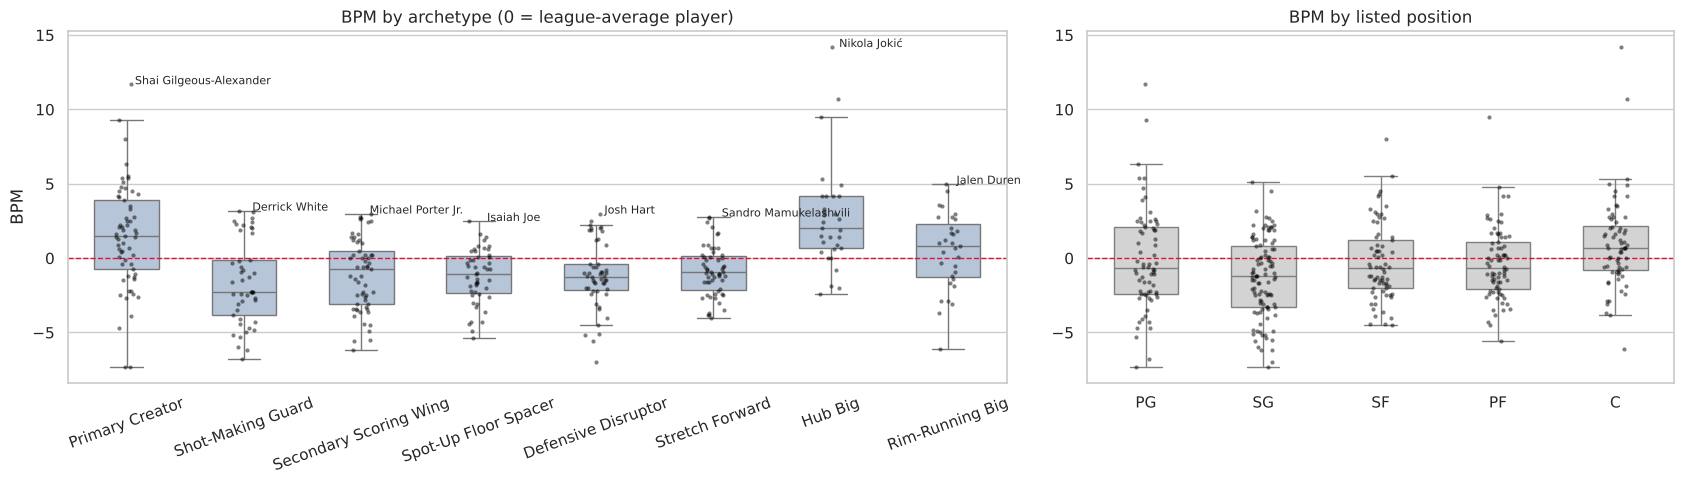

R² of value stats on group dummies (share of variance explained):
         listed position  8 archetypes
TS%                0.167         0.289
BPM                0.065         0.215
WS/48              0.157         0.242
VORP               0.044         0.205
minutes            0.019         0.072


,TS%,BPM,WS/48,VORP,minutes,BPM range (min … max)
archetype,,,,,,
Primary Creator,0.573,1.5,0.112,1.3,1752.0,-7.3 … +11.7
Shot-Making Guard,0.556,-2.3,0.059,-0.1,1320.0,-6.8 … +3.2
Secondary Scoring Wing,0.581,-0.7,0.083,0.4,1689.0,-6.2 … +3.0
Spot-Up Floor Spacer,0.597,-1.0,0.086,0.3,1377.0,-5.4 … +2.5
Defensive Disruptor,0.540,-1.2,0.080,0.2,1354.0,-7.0 … +3.0
Stretch Forward,0.590,-1.0,0.102,0.4,1192.0,-4.0 … +2.8
Hub Big,0.592,2.0,0.144,1.6,1818.0,-2.4 … +14.2
Rim-Running Big,0.664,0.8,0.156,0.9,1234.0,-6.1 … +5.0


In [16]:
VALUE = {'ts_percent': 'TS%', 'bpm': 'BPM', 'ws_48': 'WS/48', 'vorp': 'VORP', 'mp': 'minutes'}
val = full[list(VALUE)].rename(columns=VALUE)
val_prof = val.groupby(arch['archetype']).median().loc[ORDER]
val_prof['BPM range (min … max)'] = [f"{val['BPM'][arch['archetype'] == a].min():+.1f} … "
                                      f"{val['BPM'][arch['archetype'] == a].max():+.1f}" for a in ORDER]
val_r2 = pd.DataFrame({k: [group_r2(val[c], LABELS[k]) for c in VALUE.values()]
                       for k in ['listed position', '8 archetypes']}, index=VALUE.values())

fig, ax = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={'width_ratios': [1.6, 1]})
sns.boxplot(x=arch['archetype'], y=val['BPM'], order=ORDER, color='lightsteelblue', fliersize=0, width=0.55, ax=ax[0])
sns.stripplot(x=arch['archetype'], y=val['BPM'], order=ORDER, color='black', size=3, alpha=0.5, ax=ax[0])
ax[0].axhline(0, color='crimson', lw=1, ls='--')
for a in ORDER:
    i = val['BPM'][arch['archetype'] == a].idxmax()
    ax[0].annotate(names[i], (ORDER.index(a), val['BPM'][i]), xytext=(6, 0), textcoords='offset points', fontsize=8)
ax[0].set(title='BPM by archetype (0 = league-average player)', xlabel='', ylabel='BPM')
ax[0].tick_params(axis='x', rotation=20)
sns.boxplot(x=arch['pos'], y=val['BPM'], order=POS_ORDER, color='lightgrey', fliersize=0, width=0.55, ax=ax[1])
sns.stripplot(x=arch['pos'], y=val['BPM'], order=POS_ORDER, color='black', size=3, alpha=0.5, ax=ax[1])
ax[1].axhline(0, color='crimson', lw=1, ls='--')
ax[1].set(title='BPM by listed position', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

print('R² of value stats on group dummies (share of variance explained):')
print(val_r2.round(3).to_string())
val_prof.round({'TS%': 3, 'BPM': 1, 'WS/48': 3, 'VORP': 1, 'minutes': 0})

### Findings: Archetype profiles and value
Each archetype has a clear, recognisable style fingerprint (medians in the profile table):

| Archetype | Style in one line |
|---|---|
| **Primary Creator** | Highest usage and assist rate (both ≈ 26%); creates most of their own twos (only about a third assisted); the most mid-range of any group (≈ 20% of shots) |
| **Shot-Making Guard** | High usage (≈ 21%) with lead-guard passing (AST% ≈ 21) but a perimeter shot diet: half of shots are threes, only 12% at the rim, and the lowest rebound and block rates |
| **Secondary Scoring Wing** | Balanced, average-looking profile: usage ≈ 20%, 42% threes, 21% at the rim, no standout skill |
| **Spot-Up Floor Spacer** | 70% of shots are threes, the most corner threes (20% of all shots), low usage (≈ 15%); the highest share of twos assisted (71%) |
| **Defensive Disruptor** | Low usage (≈ 15%); the highest steal rate of any archetype (≈ 2.4%), a three-heavy diet, and more offensive rebounding than the other perimeter groups |
| **Stretch Forward** | Frontcourt rebounding and shot-blocking (BLK% ≈ 2.6) with ≈ 45% of shots from three: the floor-spacing big |
| **Hub Big** | Interior player who also runs the offense: usage ≈ 23%, AST% ≈ 18, the highest defensive rebound rate (≈ 23%) and the most free throws after rim-runners |
| **Rim-Running Big** | ≈ 63% of shots at the rim, almost no threes (1%), the highest offensive rebound (≈ 13%), block (≈ 4.1%) and free-throw rates, and the lowest usage (≈ 14%) |

- **Value differs by archetype, but far less than within it.** Archetype explains about 21% of the variance in BPM and
  24% in WS/48 (R² on group dummies), so most of the quality variation is *within* archetypes. Every archetype
  contains players with a negative BPM; the top BPMs in Primary Creator (+11.7, Shai Gilgeous-Alexander) and Hub Big
  (+14.2, Nikola Jokić) sit in archetypes that also hold players below −2.
- **The medians tell a coherent story.** Hub Bigs and Primary Creators have the highest median BPM (+2.0 and +1.5),
  partly because BPM rewards the box-score production these roles generate (usage, assists, rebounds). Rim-Running
  Bigs have the highest median TS% (≈ 0.66, from shots at the rim) and WS/48, yet a modest BPM. Shot-Making Guards
  have the lowest median BPM (−2.3) and WS/48 (0.059): high-usage perimeter scoring with few rim attempts, on the
  second-lowest TS% (0.556, above only the Defensive Disruptors).
- **Archetypes say more about value than positions do** (R² for BPM ≈ 0.21 vs. 0.07), because they capture role, and
  role drives box-score impact. But the main point stands: **archetypes describe style, not quality**. Knowing a
  player is a Primary Creator does not say whether they are an MVP candidate or a struggling backup.

---
## 8. Unicorns and Border Players vs. Positions

**Goal.** Cross-tabulate the anomaly categories from the anomaly-detection notebook (statistical unicorn, unique
hybrid, border player, typical) against listed position and against archetype, and compare the **rate** of each
category per position.

**Why it matters.** If one position produced most of the league's unusual players, the five-position system would be
missing that position's variety in particular. Likewise, if border players concentrated in certain positions, those
positions would be the ones where roles blur.

**What to look for.** Whether unicorns are spread evenly or concentrated, and whether border players come mainly from
the perimeter positions.

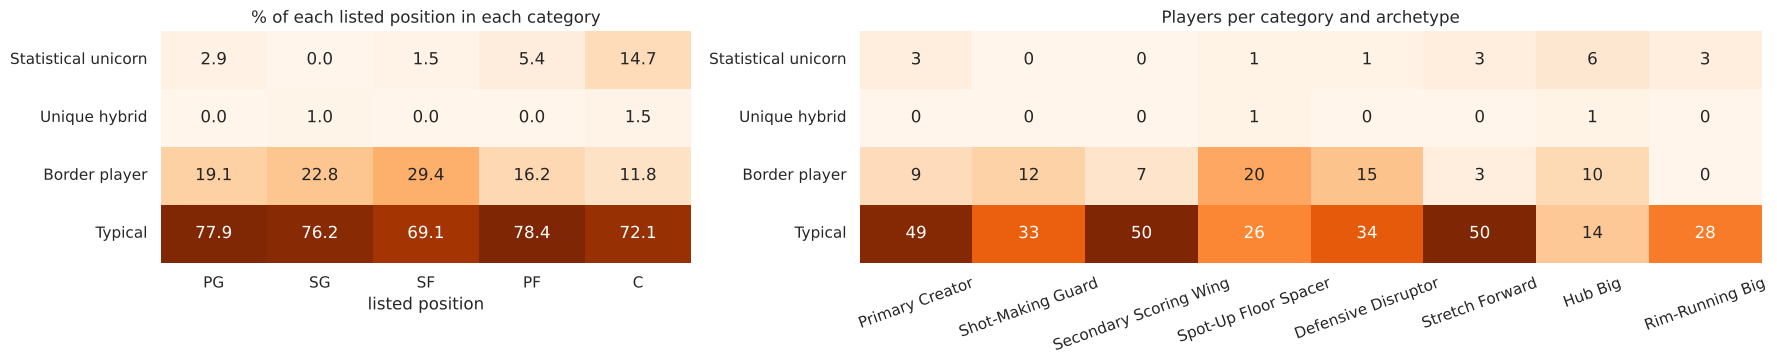

median anomaly score by listed position: {'PG': 0.52, 'SG': 0.42, 'SF': 0.42, 'PF': 0.48, 'C': 0.75}
median silhouette (own archetype) by listed position: {'PG': 0.122, 'SG': 0.115, 'SF': 0.084, 'PF': 0.134, 'C': 0.19}
unicorns + unique hybrids: 19, of which listed C: 11


pos,PG,SG,SF,PF,C
category,,,,,
Statistical unicorn,2,0,1,4,10
Unique hybrid,0,1,0,0,1
Border player,13,23,20,12,8
Typical,53,77,47,58,49


In [17]:
cat = anom['category']
CAT_ORDER = ['Statistical unicorn', 'Unique hybrid', 'Border player', 'Typical']
cat_pos = pd.crosstab(cat, arch['pos']).loc[CAT_ORDER, POS_ORDER]
cat_pos_rate = (pd.crosstab(cat, arch['pos'], normalize='columns').loc[CAT_ORDER, POS_ORDER] * 100).round(1)
cat_arch = pd.crosstab(cat, arch['archetype']).reindex(index=CAT_ORDER, columns=ORDER, fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(18, 3.8), gridspec_kw={'width_ratios': [1, 1.7]})
sns.heatmap(cat_pos_rate, annot=True, fmt='.1f', cmap='Oranges', cbar=False, ax=ax[0])
ax[0].set(title='% of each listed position in each category', xlabel='listed position', ylabel='')
sns.heatmap(cat_arch, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax[1])
ax[1].set(title='Players per category and archetype', xlabel='', ylabel='')
ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

print('median anomaly score by listed position:',
      anom['anomaly_score'].groupby(arch['pos']).median().loc[POS_ORDER].round(2).to_dict())
print('median silhouette (own archetype) by listed position:',
      arch['silhouette'].groupby(arch['pos']).median().loc[POS_ORDER].round(3).to_dict())
unicorns = arch.loc[cat.isin(['Statistical unicorn', 'Unique hybrid']), ['player', 'pos', 'archetype']]
print(f'unicorns + unique hybrids: {len(unicorns)}, of which listed C: {(unicorns["pos"] == "C").sum()}')
cat_pos

### Findings: Unicorns and border players
- **Statistical unicorns are concentrated among centres.** 10 of the 17 statistical unicorns (11 of 19 including the
  unique hybrids) are listed C, about 15% of all centres, compared with 0–6% at the other positions. Centres also have
  by far the highest median anomaly score (0.75 vs. 0.42–0.52). The "centre" label covers the widest range of extreme
  profiles: rim-runners (Powell, Robinson, Sims), hubs (Jokić, Embiid, Wembanyama, Nurkić) and stretch bigs (Drummond,
  Huff, Stewart).
- **Border players are concentrated on the perimeter.** About 29% of small forwards and 23% of shooting guards are
  border players, against 12% of centres. SF also has the lowest median archetype silhouette (≈ 0.08) and C the
  highest (≈ 0.19).
- By archetype, border players gather in Spot-Up Floor Spacer (20), Defensive Disruptor (15) and Shot-Making Guard
  (12); Rim-Running Big has none. Statistical unicorns are most common among Hub Bigs (6 of 31).
- **The two kinds of misfit point in opposite directions.** Bigs are the most *distinct* players (unicorns, high
  silhouette); wings are the most *blended* (border players, low silhouette), consistent with the listed SF being the position no
  archetype "predicts" in §3. Positions mislead in both cases: "C" lumps together very different extreme profiles, and
  "SF" / "SG" draw boundaries in the middle of a continuum.

---
## 9. Export

**Goal.** Save the validation results in one tidy table for reporting.

| `section` | Rows | Main columns |
|---|---|---|
| `ARI` | one per grouping × position pair | observed ARI, null mean / sd / max, z, permutation p |
| `R2 style feature`, `R2 held-out feature`, `R2 value stat` | one per feature | R² for listed position, 8 archetypes, 3 families |
| `confusion matrix` | listed and played position | accuracy, macro F1 of the archetype majority mapping |
| `CV` | one per target × model, plus the baseline | best setting, mean ± sd accuracy, mean ± sd macro F1 |
| `silhouette` | one per labelling | average silhouette |

In [18]:
out = DATA / 'processed'
parts = [
    perm.assign(section='ARI', item=perm['grouping'] + ' vs. ' + perm['compared with'])
        .drop(columns=['grouping', 'compared with']),
    r2.drop(columns='archetypes − position').assign(section='R2 style feature').rename_axis('item').reset_index(),
    held.drop(columns='archetypes − position').assign(section='R2 held-out feature').rename_axis('item').reset_index(),
    val_r2.assign(section='R2 value stat').rename_axis('item').reset_index(),
    pd.DataFrame({'section': 'confusion matrix', 'item': ['archetype → listed position', 'archetype → played position'],
                  'accuracy': [acc_cm, acc_cm_played], 'macro F1': [f1_cm, f1_cm_played]}),
    best.reset_index().assign(section='CV', item=lambda d: d['target'] + ' | ' + d['model'])
        [['section', 'item', 'setting', 'acc', 'acc_sd', 'f1', 'f1_sd']]
        .rename(columns={'acc': 'accuracy', 'acc_sd': 'accuracy sd', 'f1': 'macro F1', 'f1_sd': 'macro F1 sd'}),
    pd.DataFrame([{'section': 'CV', 'item': f'{t} | majority baseline', 'accuracy': b[1], 'accuracy sd': b[2],
                   'macro F1': b[3]} for t, b in base.items()]),
    sil.rename('silhouette').rename_axis('item').reset_index().assign(section='silhouette'),
]
summary = pd.concat(parts, ignore_index=True)
summary = summary[['section', 'item'] + [c for c in summary.columns if c not in ('section', 'item')]]
summary.round(4).to_csv(out / 'validation_summary.csv', index=False)
print('saved', out / 'validation_summary.csv', summary.shape)
summary.groupby('section', sort=False).size()

saved ../data/processed/validation_summary.csv (44, 17)


section
ARI                     4
R2 style feature       13
R2 held-out feature     7
R2 value stat           5
confusion matrix        2
CV                      9
silhouette              4
dtype: int64

---
## 10. Conclusions

### What the five positions capture, and what they miss

| | Five positions | Data-driven archetypes |
|---|---|---|
| Agreement with each other | — | ARI ≈ 0.14–0.18: far above chance (permutation p = 0.001) but far from a relabelling (the two position labels agree at 0.54) |
| As a confusion matrix | — | Archetype → majority position is right for 50% of players (macro F1 0.45); the listed SF is never "predicted" |
| Size (rebounding, blocks; PCA axis 1) | **Captured well** (R² ≈ 0.46–0.55) | Captured equally well; position slightly better on defensive rebounding |
| On-ball creation (usage, AST%; axis 2) | **Largely missed** (usage R² ≈ 0.05) | Captured (usage R² ≈ 0.57) |
| Disruption / shot diet (steals, mid-range, FT rate; axis 3) | **Missed** (R² ≤ 0.15) | Partly captured (R² ≈ 0.34–0.44) |
| Overall (mean R² across 13 features) | 0.27 | 0.54 (3 families: 0.39) |
| Predictable from style (5-fold CV, best KNN) | accuracy 0.59 (baseline 0.27) | 0.88 for archetypes, 0.94 for families (expected: built from the same features) |
| Compactness in style space (silhouette) | 0.023 | 0.13 (3 families: 0.21) |
| Quality (BPM, R²) | 0.07 | 0.21: archetypes describe style, not quality |

### The project's main findings
1. **Positions are a one-dimensional description of a three-dimensional game.** PCA found three style axes (interior ↔
   perimeter, on-ball creator ↔ off-ball finisher, disruptor ↔ scorer). Position tracks the first, essentially size,
   and is nearly blind to the other two. This notebook confirms it feature by feature (position explains rebounding
   and blocks but almost nothing about usage, steals or the mid-range), on the PCA map (position medians line up along
   PC1), and in prediction (a model that knows exactly how a player plays still misassigns about four positions in ten).
2. **Playing style is a continuum.** Silhouettes are low for every labelling, DBSCAN sees a single connected cloud, and
   about one player in five is a border player. Archetypes are useful *regions* of a continuous map, not separate
   species.
3. **A two-level taxonomy works.** The **3 families** (On-Ball Creator, Off-Ball Perimeter, Big) are the most robust
   structure in the data and on their own already explain more style variance than five positions. The
   **8 archetypes** add useful detail. Their reliability varies (bootstrap stability from the clustering notebook):
   Rim-Running Big is sharply separated and stable; Secondary Scoring Wing is the unstable "no specialty" middle.
4. **Every position hides several jobs.** Centres split into rim-runners, hubs and stretch bigs; point guards into
   primary creators and shot-making guards; listed small forwards have no archetype of their own, and the forward
   positions are where any position label disagrees most with the roles. Only the rim-running big
   corresponds to a single position.
5. **Unusual ≠ in-between.** Statistical unicorns are extreme versions of a role and are concentrated among centres;
   border players are ordinary profiles between two roles and are concentrated among wings.

### Limitations
- **Box-score data under-describes defence.** Only steals, blocks and rebounding enter the features; on-ball defence,
  switching and rim deterrence without a block are invisible, so defensive roles are the least reliable part of the
  taxonomy.
- **One season.** Roles change with team context, injuries and age; the archetypes describe 2025-26 only.
- **A 500-minute cut-off.** It stabilises rate stats but excludes low-minute and injured players.
- **k = 8 was chosen partly for interpretability.** The statistics support k = 3 most strongly; eight archetypes are a
  useful level of detail, not a uniquely correct number.
- **Circularity.** Archetypes and families were built from the same 13 features used in the R², silhouette and
  cross-validation comparisons, so they are favoured on those features by construction. Their scores are a ceiling,
  not an independent test; the held-out features in §4 and the value stats in §7 reduce, but do not remove, this
  advantage.
- **Position labels are themselves noisy.** Two versions of position agree only at ARI ≈ 0.54, so a perfect match was
  never achievable.

**Bottom line.** The five positions are a good shorthand for *size*. Data-driven archetypes keep that information and
add the dimensions positions miss, above all **who creates the offense**. For describing how a modern NBA player
actually plays, a family + archetype label (with a fit score) is a more informative summary than a position.